In [29]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import re
#plt.rcParams是存储全局变量的地方[font.sans-serif]是指定无衬线字体后面[ ]里面是字体名称
plt.rcParams['font.sans-serif'] = ['Microsoft YaHei'] 
# 下面代码是解决负号 '-' 显示为方块的问题
plt.rcParams['axes.unicode_minus'] = False

In [30]:
#读取数据CSV文件，encoding是为了防止含特殊字符报错
df=pd.read_csv(r"D:\AI_Usage_and_Impact_on_Students_and_Professionals.csv", encoding='ISO-8859-1')
#df.columns是获取列名组成的索引，.str是对索引中的每个字符串批量应用
#.strip()是去掉字符串首尾的空白字符（空格、\t、\n、\r 等）中间空白不受影响
df.columns = df.columns.str.strip()
print(df.columns)

Index(['User_ID', 'Age', 'Gender', 'Country', 'User_Type', 'Education_Level',
       'Profession', 'Monthly_Income', 'AI_Tool', 'AI_Purpose',
       'AI_Usage_Hours_Per_Day', 'Tasks_Performed', 'Monthly_AI_Cost',
       'Productivity_Score', 'Accuracy_Rating', 'Satisfaction_Score',
       'Time_Saved_Hours_Per_Week', 'Work_or_Study_Hours_Per_Day',
       'Would_Recommend'],
      dtype='object')


In [31]:
#遍历所有 object（字符串）列，先 astype(str) 统一类型、str.strip() 去首尾空白
#replace 把字符串 'nan' 和空串 '' 还原为真正的 np.nan，实现文本列规范化 + 缺失值统一
for c in df.select_dtypes('object').columns:
#只遍历一遍列名但df[c]取出整列得到一个一维数组series而.str可以对数组中每个元素批量应用
#字符串方法.astype(str).str.strip().replace()一次性批量处理该列“所有值”
    df[c]= df[c].astype(str).str.strip().replace({'nan': np.nan,'':np.nan})
    print(df[c])

0      U0269
1      U0217
2      U0152
3      U0264
4      U0263
       ...  
295    U0066
296    U0094
297    U0136
298    U0002
299    U0130
Name: User_ID, Length: 300, dtype: object
0          30
1          30
2          17
3          35
4          19
        ...  
295       NaN
296        43
297        48
298        31
299    36 yrs
Name: Age, Length: 300, dtype: object
0        Male
1        Male
2        Male
3      FEMALE
4      Female
        ...  
295    Female
296      Male
297      Male
298    Female
299      Male
Name: Gender, Length: 300, dtype: object
0      United Kingdom
1       United States
2              Canada
3              Brazil
4              Canada
            ...      
295     United States
296           Nigeria
297            Brazil
298          Pakistan
299     United States
Name: Country, Length: 300, dtype: object
0      Professional
1      Professional
2           Student
3      Professional
4           Student
           ...     
295    Professional
296 

In [32]:
#清洗函数
def clean_number(x):
    #判断是否是缺失值是直接返回
    if pd.isna(x): return np.nan
#str(x)转成字符串.lower()改成小写.replace()去掉单位符号
    s = str(x).lower().replace('hrs','').replace('hr','').replace('yrs','').replace('yr','')
    s = s.replace('$','').replace(',','')
    #把简单清洗的数变成float类型，失败就返回nan
    try:return float(s)
    except:return np.nan


In [33]:
for c in ['Age','Monthly_Income','Monthly_AI_Cost','AI_Usage_Hours_Per_Day',
          'Time_Saved_Hours_Per_Week','Work_or_Study_Hours_Per_Day']:
    # 遍历需要清洗的数值列df[c]取出一列数组
    # 对每列的每个元素调用.apply(clean_number)，把脏字符串统一成 float
    df[c] = df[c].apply(clean_number)    

for c in ['Productivity_Score','Accuracy_Rating','Satisfaction_Score']:
    # 遍历本应是数字的评分列
    #pd.to_numeric(df[c])把整列批量转数值错误取值为nan
    df[c] = pd.to_numeric(df[c], errors='coerce')
    # 强制转数值；errors='coerce' 表示无法转换的置为 NaN（不会报错中断）
print(df.shape)

(300, 19)


In [37]:
#.isna（）判断是否为空值.sum（）对布尔 DataFrame 按列求和
#pd.DataFrame 是 pandas 的核心数据结构，用来创建二维表格数据
missing = pd.DataFrame(
    #.mean()按列求均值缺失数/总行数，.round(2)保留2位小数
    #.sort_values('缺失数',ascending=False)排序第一个是按这一列值排序，第二个是按降序排
    #每列缺失数df.isna().sum() 或 df.isna().sum(axis=0)列是竖着的得到的结果最左边是列名
    #每行缺失数df.isna().sum(axis=1)行是横着的得到的结果最左边的是行索引
    {'缺失数':df.isna().sum(),
     '缺失率(%)':(df.isna().mean()*100).round(2)}
).sort_values('缺失数',ascending=False)
print(missing)

                             缺失数  缺失率(%)
Age                           23    7.67
Tasks_Performed               18    6.00
Productivity_Score            16    5.33
Profession                    15    5.00
Accuracy_Rating               15    5.00
AI_Purpose                    13    4.33
Education_Level               13    4.33
Monthly_AI_Cost               12    4.00
AI_Tool                       11    3.67
Time_Saved_Hours_Per_Week     10    3.33
Gender                        10    3.33
Country                       10    3.33
Monthly_Income                10    3.33
Work_or_Study_Hours_Per_Day    9    3.00
AI_Usage_Hours_Per_Day         7    2.33
Satisfaction_Score             7    2.33
Would_Recommend                5    1.67
User_Type                      0    0.00
User_ID                        0    0.00


In [38]:
print("总行数:", len(df))                       # 打印总行数，方便对照缺失数看比例
print(missing[missing['缺失数'] > 0])           
# 只打印"至少有一个缺失"的字段missing[missing['缺失数'] > 0]，避免整表噪音

总行数: 300
                             缺失数  缺失率(%)
Age                           23    7.67
Tasks_Performed               18    6.00
Productivity_Score            16    5.33
Profession                    15    5.00
Accuracy_Rating               15    5.00
AI_Purpose                    13    4.33
Education_Level               13    4.33
Monthly_AI_Cost               12    4.00
AI_Tool                       11    3.67
Time_Saved_Hours_Per_Week     10    3.33
Gender                        10    3.33
Country                       10    3.33
Monthly_Income                10    3.33
Work_or_Study_Hours_Per_Day    9    3.00
AI_Usage_Hours_Per_Day         7    2.33
Satisfaction_Score             7    2.33
Would_Recommend                5    1.67


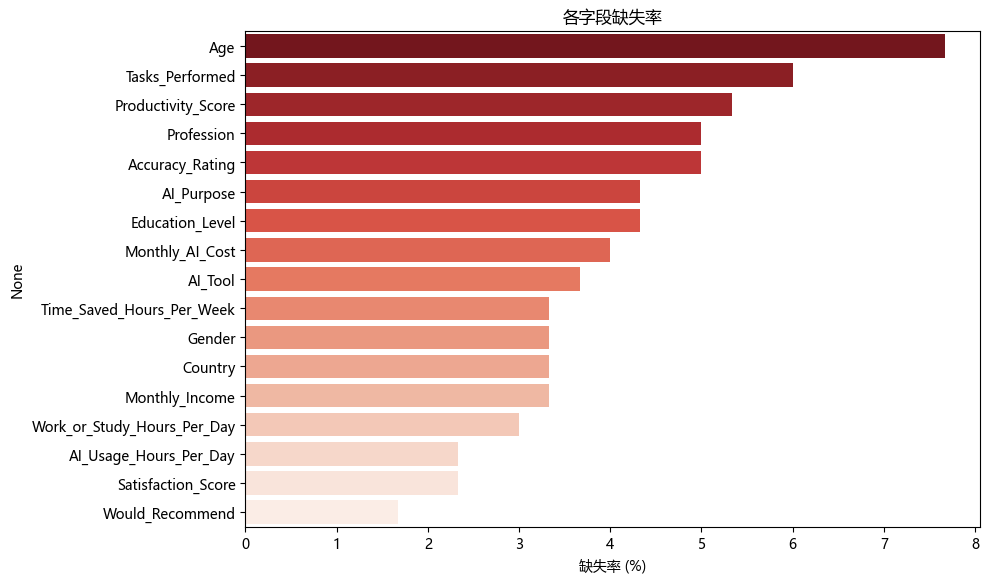

In [39]:
#注意一定要与之前的字段名一样‘缺失率’如果少了（%）会报错！！！缺失值表图
miss_plot = missing[missing['缺失数'] > 0]      # 筛出有缺失的字段用于绘图
if len(miss_plot) > 0:                          # 如果有缺失才画图
    #figsize=(宽, 高)，高 = max(3, 字段数 × 0.35) → 高度自适应
    # 创建画布；高度随字段数自适应（每个字段约0.35英寸，最少3英寸），防止标签挤在一起
    plt.figure(figsize=(10, max(3, len(miss_plot)*0.35)))
    # 画水平条形图：x为缺失率，y为字段名；红配色（越深缺失越多）
    #hue=miss_plot.index按字段名分组着色（每个条不同色）
    #palette='Reds_r'配色方案：Reds_r = 红色系反转（_r = reverse）
    #legend=False不显示图例（每条已有 y 标签，图例多余）
    sns.barplot(x=miss_plot['缺失率(%)'], y=miss_plot.index,
            hue=miss_plot.index, palette='Reds_r', legend=False)
    plt.title('各字段缺失率')                    # 图标题
    plt.xlabel('缺失率 (%)')                     # x轴标签
    plt.tight_layout()                          # 自动调整布局，防止标签被裁掉
    plt.show()                                  # 显示图
else:
    print("无缺失值")                            # 若无缺失则文字提示

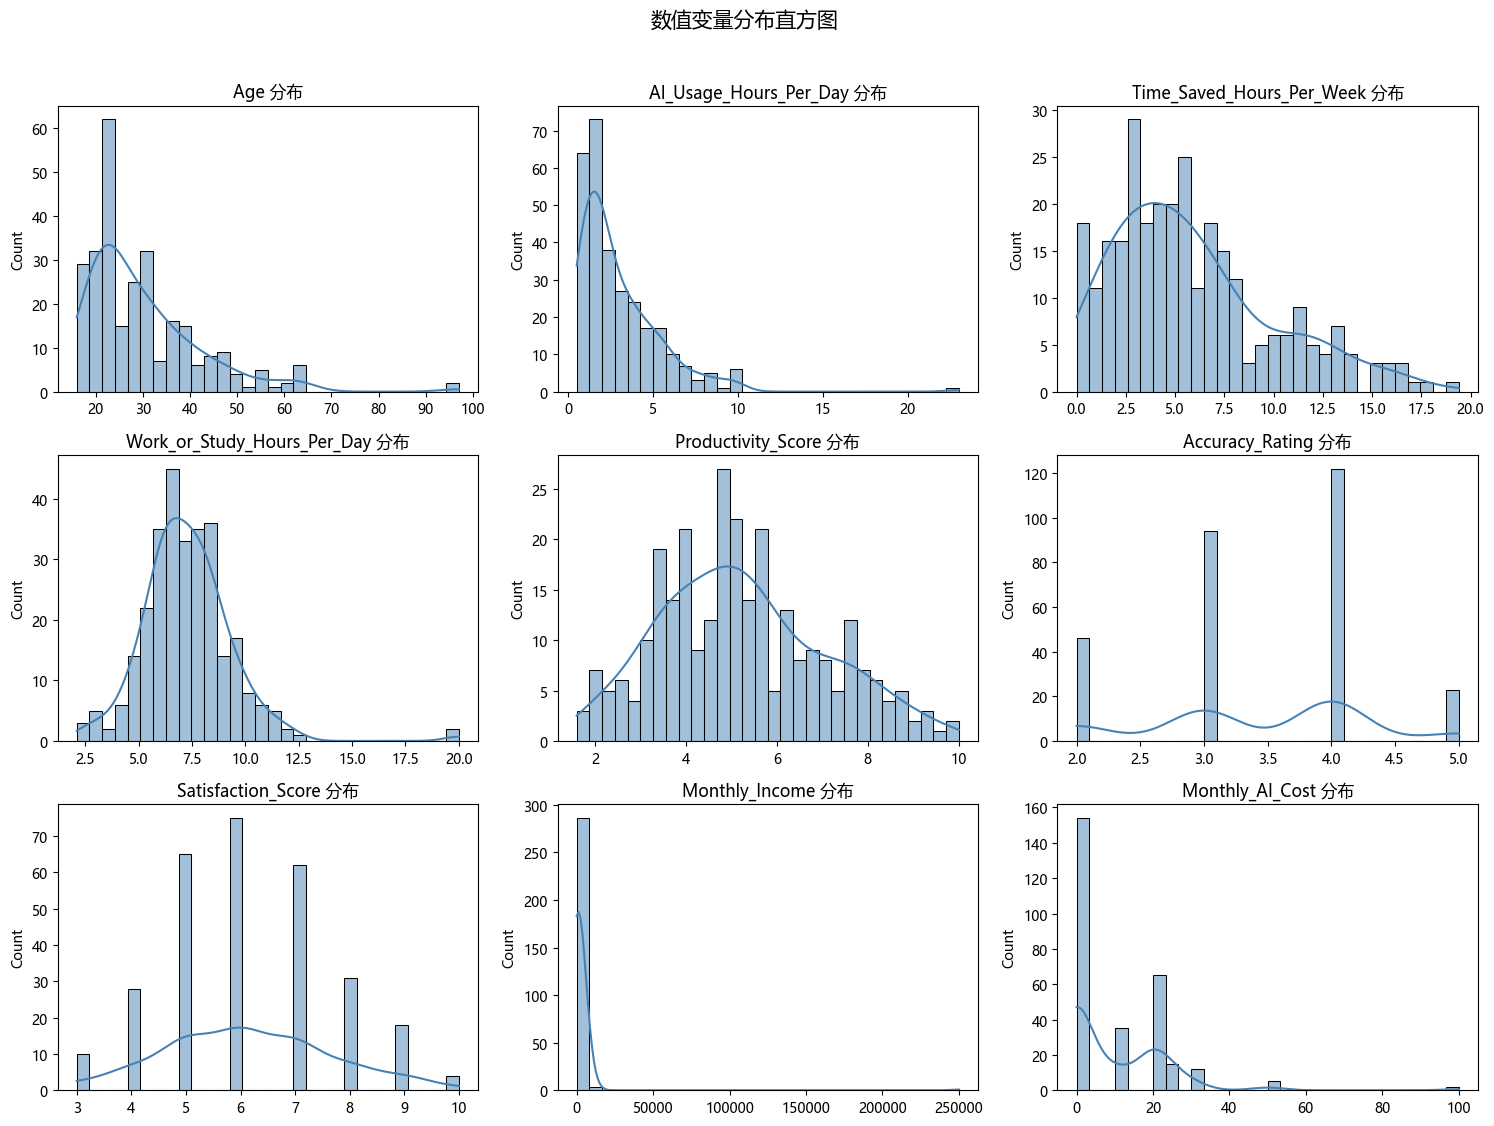

Monthly_Income                 16.52
AI_Usage_Hours_Per_Day          2.71
Monthly_AI_Cost                 2.51
Age                             1.92
Work_or_Study_Hours_Per_Day     1.49
Time_Saved_Hours_Per_Week       0.87
Productivity_Score              0.37
Satisfaction_Score              0.19
Accuracy_Rating                -0.17
dtype: float64


In [43]:
#观察分布表图
num_cols = ['Age','AI_Usage_Hours_Per_Day','Time_Saved_Hours_Per_Week',
            'Work_or_Study_Hours_Per_Day','Productivity_Score',
            'Accuracy_Rating','Satisfaction_Score','Monthly_Income','Monthly_AI_Cost']
# 列出想观察分布的数值列（共9个）
num_cols = [c for c in num_cols if c in df.columns]
# 过滤掉数据里实际不存在的列，避免 KeyError（防止列名对不上）
fig, axes = plt.subplots(3, 3, figsize=(15, 11))
# 创建 3行×3列 的子图网格，画布 15×11 英寸
# 把 3×3 的二维坐标轴数组拉平成一维，方便循环索引
#好处：循环时用 axes[i] 一个下标就能依次取子图，不用算行列坐标
axes = axes.flatten()                       
#enumerate(num_cols)：同时拿到 序号 i 和 列名 c 遍历每个数值列，i 是子图序号，c 是列名
for i, c in enumerate(num_cols):
#df[c].dropna()	取该列，去掉缺失值（直方图不接受 NaN，否则报错/异常）
#bins=30	分成 30 个区间（柱子数量）
#kde=True	叠加核密度曲线（KDE），平滑展示分布形状
#ax=axes[i]	画到第 i 个子图上（关键！不指定会画到当前活动图）
#color='steelblue'	统一用钢蓝色
    sns.histplot(df[c].dropna(), bins=30, kde=True, ax=axes[i], color='steelblue')
    axes[i].set_title(f'{c} 分布')            # 子图标题显示列名
    axes[i].set_xlabel('')                   # 清空x轴标签（列名已在标题里，避免重复）
for j in range(len(num_cols), len(axes)):    # 若列数不足9个，剩下的子图位置
    axes[j].axis('off')                      # 把多余子图关掉（不显示空白框）
plt.suptitle('数值变量分布直方图', fontsize=15, y=1.02)
# 给整张图加总标题；y=1.02 让标题略微上移，不压住子图
plt.tight_layout()                           # 自动调整子图间距
plt.show()                                   # 显示

print(df[num_cols].skew().sort_values(ascending=False).round(2))
# 计算各列偏度（>0右偏，<0左偏，|值|>1偏态明显），降序排列并保留2位小数

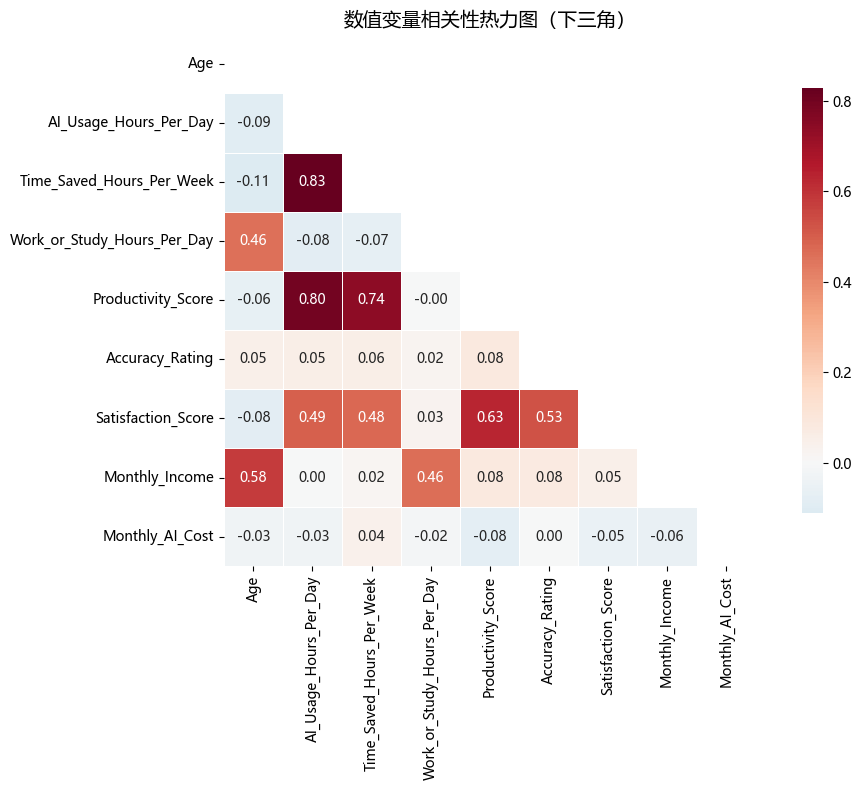

与 Productivity_Score 相关性排序：
AI_Usage_Hours_Per_Day         0.798
Time_Saved_Hours_Per_Week      0.744
Satisfaction_Score             0.629
Accuracy_Rating                0.081
Monthly_Income                 0.081
Monthly_AI_Cost               -0.077
Age                           -0.064
Work_or_Study_Hours_Per_Day   -0.003
Name: Productivity_Score, dtype: float64


In [46]:
#数值变量相关性热力图
corr_cols = ['Age','AI_Usage_Hours_Per_Day','Time_Saved_Hours_Per_Week',
             'Work_or_Study_Hours_Per_Day','Productivity_Score',
             'Accuracy_Rating','Satisfaction_Score','Monthly_Income','Monthly_AI_Cost']
# 列出参与相关性分析的数值列

corr_cols = [c for c in corr_cols if c in df.columns]
# 再次过滤实际存在的列

corr = df[corr_cols].corr(method='spearman')
# 计算 Pearson 相关系数矩阵（-1 到 1）；两两变量间的线性相关强度

plt.figure(figsize=(11, 8))                  # 创建 11×8 画布
mask = np.triu(np.ones_like(corr, dtype=bool))
# 生成上三角布尔掩码（True在上三角），用于遮住右上重复部分，只留下三角，图更清爽
sns.heatmap(corr, mask=mask, annot=True, fmt='.2f', cmap='RdBu_r',
            center=0, square=True, linewidths=.5, cbar_kws={'shrink': .8})
# 画热力图：mask遮上三角；annot=True 格子里显示数值；fmt='.2f' 保留2位小数；
# cmap='RdBu_r' 红蓝发散配色；center=0 让0值对应白色；square=True 每格为正方形；
# linewidths=.5 格子间加细线分隔；cbar_kws 让颜色条短一点
plt.title('数值变量相关性热力图（下三角）', fontsize=14)   # 图标题
plt.tight_layout()                           # 自动布局
plt.show()                                   # 显示

if 'Productivity_Score' in corr.columns:     # 若存在生产力列才做以下分析
    print("与 Productivity_Score 相关性排序：")
    print(corr['Productivity_Score'].drop('Productivity_Score').sort_values(key=abs, ascending=False).round(3))
    # 取生产力那一列 → 去掉它自己（自相关恒为1）→ 按绝对值从大到小排序（正负相关都算强）
    # → 保留3位小数，找出与生产力关系最强的变量

候选分组列： ['User_ID', 'Gender', 'Country', 'User_Type', 'Education_Level', 'Profession', 'AI_Tool', 'AI_Purpose', 'Tasks_Performed', 'Would_Recommend']
使用分组列： Profession
                                                 AI_Usage_Hours_Per_Day  \
                                                                   mean   
Profession                                                                
AI Content Strategist                                               4.4   
AI Customer Success Manager                                         1.7   
AI Customer Support Specialist                                      5.2   
AI-Powered Customer Support Executive                               0.9   
Academic Research Professor and Technical Writer                    4.3   
...                                                                 ...   
Softwareentwickler (Software Developer)                             2.9   
Softwareentwicklerin (Software Developer)                           4.0   
Statisti

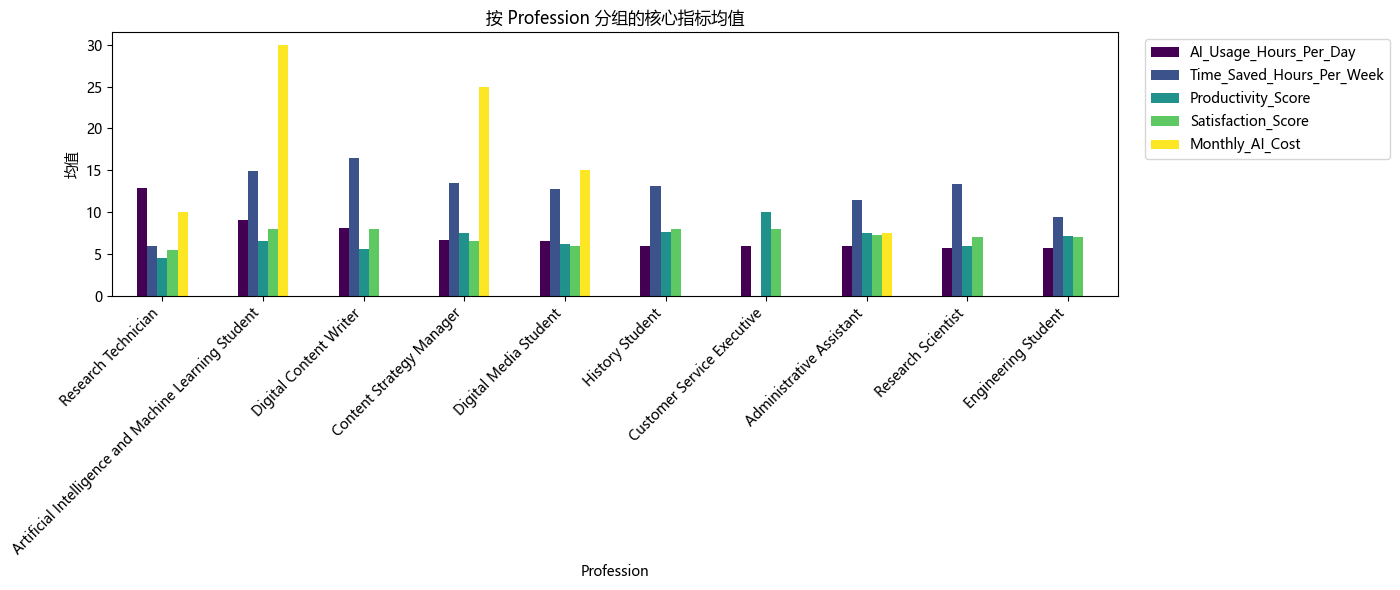

In [50]:
cat_cols = df.select_dtypes('object').columns.tolist()
# 取出所有文本类型的列名并转成列表，这些是潜在的分组维度（职业、身份等）
print("候选分组列：", cat_cols)               # 打印出来方便确认哪个列适合分组

group_col = None                             # 初始化分组列变量为空
for cand in ['Occupation','Profession','User_Type','Role','Status','Student_or_Professional']:
    # 按优先级依次尝试常见分组列名
    if cand in df.columns:                   # 如果某候选列名确实存在
        group_col = cand; break              # 就用它作为分组列并跳出循环
if group_col is None and cat_cols:           # 如果上面都没匹配到，但存在文本列
    group_col = cat_cols[0]                  # 退而求其次用第一个文本列兜底
print("使用分组列：", group_col)              # 打印最终选用的分组列，便于核对

agg_cols = [c for c in ['AI_Usage_Hours_Per_Day','Time_Saved_Hours_Per_Week',
                        'Productivity_Score','Satisfaction_Score','Monthly_AI_Cost']
            if c in df.columns]
# 选出要聚合的数值指标列（且必须实际存在）

group_summary = (df.groupby(group_col)[agg_cols]
                   .agg(['mean','median','count'])
                   .round(2))
# 按分组列分组 → 只取数值指标 → 对每组算均值、中位数、样本数 → 保留2位小数
# 均值看整体、中位数抗极端值、count看每组样本量是否够
print(group_summary)                         # 打印完整分组统计表

mean_table = df.groupby(group_col)[agg_cols].mean().round(2).sort_values(agg_cols[0], ascending=False)
# 单独算均值表 → 按第一个指标（如AI使用时长）降序排列，一眼看出谁用得最多
print("\n各群体均值：\n", mean_table)        # 打印均值对比表

top_n = 10
mean_table_top = mean_table.head(top_n)
print(f"\n仅展示前 {top_n} 个分组")
mean_table_top.plot(kind='bar', figsize=(14, 6), colormap='viridis')
# 用均值表画分组柱状图，viridis 渐变色，画布 12×5
plt.title(f'按 {group_col} 分组的核心指标均值')   # 标题里带上分组列名
plt.ylabel('均值')                           # y轴标签
plt.xticks(rotation=45, ha='right',fontsize=10)          # x轴标签旋转30度、右对齐，防止长名字重叠
plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left')   # 图例移到图右侧外部，不挡柱子
plt.tight_layout()                           # 自动布局
plt.show()                                   # 显示

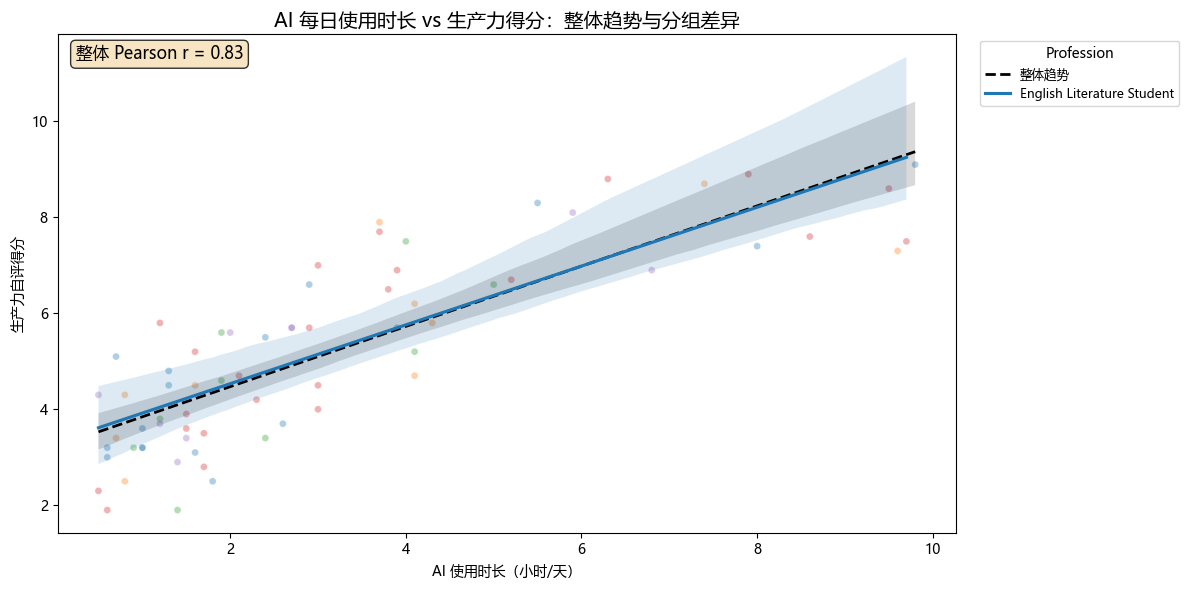

In [47]:
plot_df = df.dropna(subset=['AI_Usage_Hours_Per_Day','Productivity_Score']).copy()
# 只保留两个关键变量都非空的记录（画图必须有x和y）；.copy() 避免后续操作触发 SettingWithCopy 警告

if group_col:                                # 如果前面成功识别到分组列
    plot_df = plot_df.dropna(subset=[group_col])   # 再去掉分组列缺失的行
    top_groups = plot_df[group_col].value_counts().head(5).index
    # 统计每组样本量，取最多的前5组（太多组会让图例和线条乱成一团）
    plot_df = plot_df[plot_df[group_col].isin(top_groups)]
    # 只保留这前5组的行

plt.figure(figsize=(12, 6))                  # 创建 12×6 画布

sns.scatterplot(data=plot_df, x='AI_Usage_Hours_Per_Day', y='Productivity_Score',
                hue=group_col if group_col else None,
                alpha=0.35, s=25, palette='tab10', legend=False)
# 画背景散点：x=AI时长，y=生产力；hue按组着色（无组则不着色）；
# alpha=0.35 半透明（点很多时避免糊成一片）；s=25 点大小；tab10 十色配色；legend=False 散点不加图例（后面趋势线统一加）

sns.regplot(data=plot_df, x='AI_Usage_Hours_Per_Day', y='Productivity_Score',
            scatter=False, color='black', line_kws={'lw':2, 'ls':'--'}, label='整体趋势')
# 叠加整体线性回归趋势线：scatter=False 不重复画点；黑色虚线；label供图例显示

if group_col:                                # 如果有分组
    for g in plot_df[group_col].unique():    # 遍历每个组
        sub = plot_df[plot_df[group_col] == g]   # 取出该组子集
        if len(sub) >= 20:                   # 样本量≥20才画趋势线（太少回归不可信）
            sns.regplot(data=sub, x='AI_Usage_Hours_Per_Day', y='Productivity_Score',
                        scatter=False, label=str(g))
            # 给该组画一条回归趋势线，并带组名标签进图例

r = plot_df[['AI_Usage_Hours_Per_Day','Productivity_Score']].corr().iloc[0,1]
# 计算这两列的 Pearson 相关系数；iloc[0,1] 取矩阵中非对角线的那个值
plt.text(0.02, 0.95, f'整体 Pearson r = {r:.2f}', transform=plt.gca().transAxes,
         fontsize=12, bbox=dict(boxstyle='round', fc='wheat', alpha=.8))
# 在图左上角（相对坐标0.02,0.95）写字显示相关系数；
# transform=plt.gca().transAxes 表示用"相对坐标"定位（0-1范围）；加圆角米色底框提升可读性

plt.title('AI 每日使用时长 vs 生产力得分：整体趋势与分组差异', fontsize=14)   # 图标题
plt.xlabel('AI 使用时长（小时/天）')          # x轴标签
plt.ylabel('生产力自评得分')                  # y轴标签
plt.legend(title=group_col, bbox_to_anchor=(1.02,1), loc='upper left', fontsize=9)
# 图例放到图右侧外部；标题用分组列名；字号9防止太长
plt.tight_layout()                           # 自动布局
plt.show()                                   # 显示